<a href="https://colab.research.google.com/github/MarcoLuw/QoE-MOS-Prediction/blob/main/model_training/xgboost_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature description

| # | Column | Category | Meaning / Practical Use | Values / Details from README |
|---|--------|----------|--------------------------|------------------------------|
| 1 | id | Identifier | Unique identifier of the sample (one video-viewing test record). | Not further defined in README |
| 2 | user_id | Identifier | Identifier of the tester who performed the session; links multiple samples to the same person. | Not further defined in README |
| 3 | QoA_VLCresolution | Video (QoA) | The actual picture resolution at which the video was played in VLC during the session, i.e. how many vertical lines of detail were rendered on screen. In practice it tells you whether the user watched a lower-detail or higher-detail version of the clip. | README notes resolution is a class identifier with values 240p and 360p |
| 4 | QoA_VLCbitrate | Video (QoA) | The video bitrate reported by VLC, i.e. the amount of video data per second during playback; higher values mean more data and generally better image quality. | Not further defined in README |
| 5 | QoA_VLCframerate | Video (QoA) | The playback frame rate reported by VLC, i.e. how many video frames per second were shown; relates to motion smoothness. | Not further defined in README |
| 6 | QoA_VLCdropped | Video (QoA) | The count of video frames dropped by VLC during playback; a measure of rendering/decoding loss experienced by the user. | Not further defined in README |
| 7 | QoA_VLCaudiorate | Video (QoA) | The audio bitrate/rate reported by VLC for the session's sound track. | Not further defined in README |
| 8 | QoA_VLCaudioloss | Video (QoA) | The amount of audio lost during playback as reported by VLC; relates to sound dropouts. | Not further defined in README |
| 9 | QoA_BUFFERINGcount | Video (QoA) | The number of buffering (stalling) events that occurred during the video session; how many times playback paused to rebuffer. | Not further defined in README |
| 10 | QoA_BUFFERINGtime | Video (QoA) | The total time spent buffering/stalling during the session; the cumulative duration playback was interrupted. | Not further defined in README |
| 11 | QoS_type | Network (QoS) | The mobile network access technology used during the test. | Coded: 1=EDGE, 2=UMTS, 3=HSPA, 4=HSPAP, 5=LTE |
| 12 | QoS_operator | Network (QoS) | The French mobile network operator used for the session. | Coded: 1=SFR, 2=BOUYGUES, 3=ORANGE, 4=FREE |
| 13 | QoD_model | Device (QoD) | The model of the device (phone or tablet) used by the tester. | Not further defined in README |
| 14 | QoD_os-version | Device (QoD) | The Android OS version running on the test device. | Not further defined in README |
| 15 | QoD_api-level | Device (QoD) | The Android API level of the device (the platform API number associated with the OS version). | Not further defined in README |
| 16 | QoU_sex | User (QoU) | The tester's gender. | Coded: 0=Woman, 1=Man |
| 17 | QoU_age | User (QoU) | The tester's age. | README states testers were aged 19 to 38 |
| 18 | QoU_study | User (QoU) | The tester's highest education level. | Coded: 5=University, 4=Secondary school, 3=College, 2=Primary school, 1=Other |
| 19 | QoF_begin_time | Feedback (QoF) | The begin time of the video session (when the viewing started). | Not further defined in README |
| 20 | QoF_shift | Feedback (QoF) | A shift value related to the session. | Not further defined in README |
| 21 | QoF_audio | Feedback (QoF) | User feedback relating to the audio of the session. | Not further defined in README |
| 22 | QoF_video | Feedback (QoF) | User feedback relating to the video of the session. | Not further defined in README |
| 23 | MOS | Target / Score | Mean Opinion Score the tester gives at the end of each video view; the subjective quality rating used as the label. | Coded: 5=Excellent, 4=Good, 3=Fair, 2=Poor, 1=Bad |

# Download dataset

GitHub Link: https://github.com/Lamyne/Poqemon-QoE-Dataset

In [2]:
!wget https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv -O ~/pokemon.csv
# !wget https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py

--2026-11-09 14:00:44--  https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8002::154, 2606:50c0:8003::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158675 (155K) [text/plain]
Saving to: ‘/mnt/hdd/homes/hlu/pokemon.csv’

/mnt/hdd/homes/hlu/ 100%[===================>] 154.96K  --.-KB/s    in 0.04s   

2026-11-09 14:00:45 (3.88 MB/s) - ‘/mnt/hdd/homes/hlu/pokemon.csv’ saved [158675/158675]



In [3]:
!ls

random_forest.ipynb  xgboost_regression.ipynb


# Python package import

If XGBoost is not installed, run: `!pip install xgboost`

In [4]:
# !uv pip install xgboost

In [5]:
import pandas as pd
import numpy as np
# import visualization
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# The following is to be able to mount Google Drive
# from google.colab import drive
import pickle # To save the model
from os.path import isfile

In [6]:
FEATURES = ["QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate",
            "QoA_VLCdropped", "QoA_VLCaudiorate", "QoA_VLCaudioloss",
            "QoA_BUFFERINGcount", "QoA_BUFFERINGtime"]
TARGET = "MOS"

In [7]:
df = pd.read_csv("~/pokemon.csv")

In [8]:
df.head()

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


# Data Preprocessing

- Remove duplications
- Remove error values
- Handle missing values

In [9]:
def preprocess(df):
  df = df.drop_duplicates(keep="first") # drop duplications
  df = df[df["QoA_VLCresolution"] != 16]  # drop error values
  df = df.dropna(subset=FEATURES + [TARGET]) # drop missing values
  df = df.reset_index(drop=True)

  X = df[FEATURES]
  y = df[TARGET]
  return X, y

# Prepare data

In [10]:
def prepare_data(X, y):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )

  # feature engineering: transform (de-skew) - no need for tree-based models
  # pt = PowerTransformer(method="yeo-johnson")
  # X_train = pt.fit_transform(X_train)
  # X_test = pt.transform(X_test)

  # scale
  scaler = StandardScaler()
  X_train = scaler.fit_transform(X_train)
  X_test = scaler.transform(X_test)

  return X_train, X_test, y_train, y_test, scaler

In [11]:
X, y = preprocess(df)
X_train, X_test, y_train, y_test, scaler = prepare_data(X, y)

# Training an XGBoost model

## Define grid params

In [12]:
# number of boosting rounds (trees)
n_estimators = [100, 300, 500]

# max depth of a tree
max_depth = [3, 5, 7, 10]

# learning rate (shrinkage) - XGBoost specific, key knob
learning_rate = [0.01, 0.05, 0.1, 0.3]

# fraction of samples used per tree (row subsampling)
subsample = [0.6, 0.8, 1.0]

# fraction of features used per tree (column subsampling)
colsample_bytree = [0.6, 0.8, 1.0]

# minimum loss reduction to make a split (regularization, like pruning)
gamma = [0, 0.1, 0.5, 1]

# minimum sum of instance weight needed in a child
min_child_weight = [1, 3, 5]

# L2 regularization term on weights
reg_lambda = [0.1, 1, 10]

# L1 regularization term on weights
reg_alpha = [0, 0.1, 1]

grid_param = {
    'n_estimators': n_estimators,
    'max_depth': max_depth,
    'learning_rate': learning_rate,
    'subsample': subsample,
    'colsample_bytree': colsample_bytree,
    'gamma': gamma,
    'min_child_weight': min_child_weight,
    'reg_lambda': reg_lambda,
    'reg_alpha': reg_alpha,
}

## Random Grid Search

The grid above spans a large number of combinations x 5 k-fold, a very large computational expense.

`RandomizedSearchCV` helps to overcome the hurdle by randomly sampling a specified number of possible candidate models.

For example, only randomly sample 200 models.

In [13]:
# The search parallelizes across 200x5 fits (all CPUs) (n_jobs = -1)
# while each individual model trains single-threaded (n_jobs = 1)
regressor = XGBRegressor(random_state=4, n_jobs=1, objective='reg:squarederror')
search = RandomizedSearchCV(
                            scoring='neg_root_mean_squared_error',
                            estimator=regressor,
                            param_distributions=grid_param,
                            n_iter=50, # We just test 200 configurations
                            verbose=2,
                            random_state=42, # Random state of GridSearch only
                            n_jobs=-1, # Train models in parallel using all CPUs
                            cv=5 # 5-fold validation
                          )

In [14]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END colsample_bytree=0.8, gamma=0, learning_rate=0.01, max_depth=5, min_child_weight=1, n_estimators=100, reg_alpha=0, reg_lambda=0.1, subsample=0.6; total time=   0.2s
[CV] END colsample_bytree=0.6, gamma=0, learning_rate=0.01, max_depth=10, min_child_weight=3, n_estimators=300, reg_alpha=1, reg_lambda=1, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=1.0, gamma=1, learning_rate=0.1, max_depth=3, min_child_weight=1, n_estimators=100, reg_alpha=1, reg_lambda=0.1, subsample=1.0; total time=   0.0s
[CV] END colsample_bytree=1.0, gamma=1, learning_rate=0.1, max_depth=3, min_child_weight=1, n_estimators=100, reg_alpha=1, reg_lambda=0.1, subsample=1.0; total time=   0.0s
[CV] END colsample_bytree=0.6, gamma=0.5, learning_rate=0.3, max_depth=7, min_child_weight=3, n_estimators=100, reg_alpha=1, reg_lambda=10, subsample=0.8; total time=   0.0s
[CV] END colsample_bytree=0.6, gamma=0.1, learning_rate=0.1, max_depth=

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to 

## Get best model

In [15]:
print(search.best_params_)
best_model = search.best_estimator_

{'subsample': 0.6, 'reg_lambda': 10, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.01, 'gamma': 1, 'colsample_bytree': 1.0}


With this best model, we try to (re)train it on the whole dataset

In [16]:
best_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


# Evaluating Model

In [17]:
y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

RMSE: 0.7416606840328135
MAE : 0.509908139705658
R2  : 0.5237891674041748


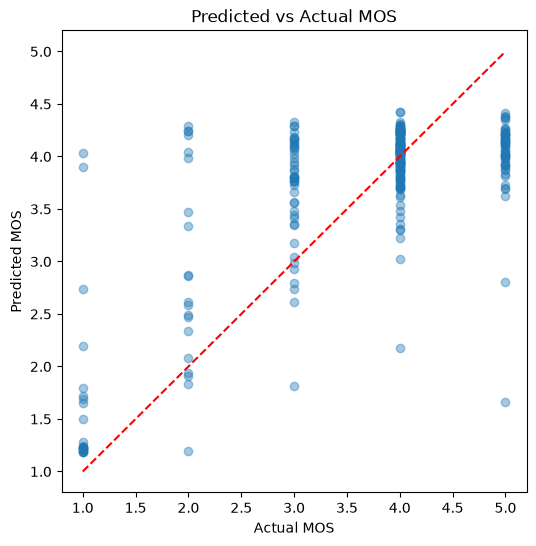

In [18]:
# Predicted vs actual MOS
title = "Predicted vs Actual MOS"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# diagonal reference line (perfect prediction)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')

plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title(title)
plt.show()

# Save model

## On Google Colab

In [19]:
# mount_point = '/content/drive'
# drive.mount(mount_point, force_remount=True)
# drive_path = mount_point + '/My Drive/'

# save_path = drive_path + 'Colab Notebooks/TSP - Data Science/Project/Models/'
# filename = save_path + f'RF.pkl'
# pickle.dump(best_model, open(filename, 'wb'))

In [20]:
%cd $save_path
!ls

[Errno 2] No such file or directory: '$save_path'
/mnt/hdd/homes/hlu/QoE-MOS-Prediction/model_training
random_forest.ipynb  xgboost_regression.ipynb


Optional: create a function to reduce duplication

In [21]:
# def search_or_load(model_filename, search, X_train, y_train):
#   if (isfile(model_filename)):
#     print("Loading model")
#     model = pickle.load(open(model_filename, 'rb'))

#   else:
#     print("Searching the best hyper_parameters")
#     search.fit(X_train, y_train)
#     print(search.best_params_)
#     model = search.best_estimator_
#     print("Training model")
#     model.fit(X_train,y_train)
#     pickle.dump(model, open(model_filename, 'wb'))
#     print("Model saved in in file ", model_filename)
#   return model

## On Linux

In [23]:
from pathlib import Path
from datetime import datetime

model_tag = "XGB"
model_artifact = f'{model_tag}.pkl'

# Timestamp for this run, to avoid overwriting previous runs
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Always under home, in a dedicated results folder
SAVE_PATH = Path.home() / "ds_result" / timestamp
SAVE_PATH.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = str(SAVE_PATH / model_artifact)

pickle.dump(best_model, open(FINAL_MODEL_PATH, 'wb'))

print("Final model path:", FINAL_MODEL_PATH)

Final model path: /mnt/hdd/homes/hlu/ds_result/20261109_141139/XGB.pkl
